<a href="https://colab.research.google.com/github/nivethashrikm08-blip/MLA0202-FML/blob/main/ML2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Dataset:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes

Final Specific Boundary (S):
['Sunny', 'Warm', '?', 'Strong', '?', '?']

Final General Boundary (G):
['Sunny', '?', '?', '?', '?', '?']
['?', 'Warm', '?', '?', '?', '?']

All hypotheses are bounded by S and G.


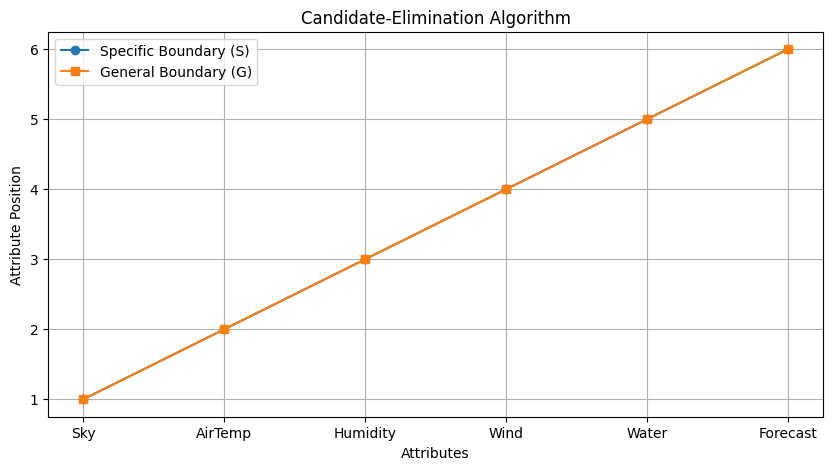

In [1]:

# Candidate-Elimination Algorithm with Graph

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Create training dataset
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

# Step 2: Save dataset as CSV
df.to_csv('training_data.csv', index=False)

# Step 3: Read CSV file
df = pd.read_csv('training_data.csv')

print("Training Dataset:")
print(df)

# Step 4: Separate attributes and target
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

num_attributes = X.shape[1]

# Step 5: Initialize S and G
S = ['Ø'] * num_attributes
G = [['?'] * num_attributes]

# Function to check hypothesis
def is_consistent(h, x):
    return all(h[i] == '?' or h[i] == x[i]
               for i in range(len(h)))

# Step 6: Candidate-Elimination
for x, target in zip(X, y):

    if target == 'Yes':

        # Remove inconsistent hypotheses from G
        G = [g for g in G if is_consistent(g, x)]

        # Generalize S
        for i in range(num_attributes):
            if S[i] == 'Ø':
                S[i] = x[i]
            elif S[i] != x[i]:
                S[i] = '?'

    else:

        # Remove inconsistent hypotheses from S
        if is_consistent(S, x):
            for i in range(num_attributes):
                if S[i] == '?':
                    continue
                if S[i] != x[i]:
                    continue

        # Specialize G
        new_G = []

        for g in G:
            if is_consistent(g, x):
                for i in range(num_attributes):
                    if g[i] == '?':
                        if S[i] != '?' and S[i] != x[i]:
                            new_h = g.copy()
                            new_h[i] = S[i]
                            new_G.append(new_h)
            else:
                new_G.append(g)

        G = new_G

# Step 7: Display final boundaries
print("\nFinal Specific Boundary (S):")
print(S)

print("\nFinal General Boundary (G):")
for g in G:
    print(g)

print("\nAll hypotheses are bounded by S and G.")

# Step 8: Plot graph
plt.figure(figsize=(10, 5))

attributes = ['Sky', 'AirTemp', 'Humidity',
              'Wind', 'Water', 'Forecast']

plt.plot(attributes,
         [i + 1 for i in range(len(S))],
         marker='o', label='Specific Boundary (S)')

plt.plot(attributes,
         [i + 1 for i in range(len(G[0]))],
         marker='s', label='General Boundary (G)')

plt.title("Candidate-Elimination Algorithm")
plt.xlabel("Attributes")
plt.ylabel("Attribute Position")
plt.legend()
plt.grid(True)
plt.show()
